<a href="https://colab.research.google.com/github/PavithraR297/App-Development-bookstore/blob/main/Yield_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# General

In [ ]:
# Imports
import numpy as np
import pandas as pd

import sklearn
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Define url to data
resource_folder = 'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res'

pesticides_url = '{}/pesticides.csv?token=AEEE4P7JUYWTGUEXQFQFP6TAN4NLQ'.format(resource_folder)
rainfall_url = '{}/rainfall.csv?token=AEEE4P6QEF6CK5DAD7EOWP3AN4NLU'.format(resource_folder)
temperature_url = '{}/temp.csv?token=AEEE4P5INYQIFOKMOSCRDP3AN4NLW'.format(resource_folder)
yield_url = '{}/yield.csv?token=AEEE4PYVSV3JAZO4CSXFA43AN4NL2'.format(resource_folder)

In [ ]:
# Load data
pesticides_data = pd.read_csv(pesticides_url, sep=',')
rainfall_data = pd.read_csv(rainfall_url, sep=', ')
temperature_data = pd.read_csv(temperature_url, sep=', ')
yield_data = pd.read_csv(yield_url, sep=',')

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:3: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  This is separate from the ipykernel package so we can avoid doing imports until
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:4: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  after removing the cwd from sys.path.


#Data Preparation


## Rainfall data

In [ ]:
rainfall_data

,Rainfall - (MM),Year,Statistics,Country,ISO3
0,55.74480,1901,Jan Average,Afghanistan,AFG
1,13.94800,1901,Feb Average,Afghanistan,AFG
2,43.84640,1901,Mar Average,Afghanistan,AFG
3,26.96100,1901,Apr Average,Afghanistan,AFG
4,52.95790,1901,May Average,Afghanistan,AFG
...,...,...,...,...,...
272827,2.03926,2016,Aug Average,Zimbabwe,ZWE
272828,0.48070,2016,Sep Average,Zimbabwe,ZWE
272829,9.13410,2016,Oct Average,Zimbabwe,ZWE
272830,72.95080,2016,Nov Average,Zimbabwe,ZWE


In [ ]:
rainfall_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 272832 entries, 0 to 272831
Data columns (total 5 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Rainfall - (MM)  272832 non-null  float64
 1   Year             272832 non-null  int64  
 2   Statistics       272832 non-null  object 
 3   Country          272832 non-null  object 
 4   ISO3             272832 non-null  object 
dtypes: float64(1), int64(1), object(3)
memory usage: 10.4+ MB


In [ ]:
rainfall_data.describe()

,Rainfall - (MM),Year
count,272832.000000,272832.000000
mean,103.470868,1958.500000
std,113.231867,33.485133
min,0.000000,1901.000000
25%,24.168375,1929.750000
50%,66.431550,1958.500000
75%,149.647250,1987.250000
max,2699.190000,2016.000000


In [ ]:
# Number of countries
len(rainfall_data['Country'].unique())

196

In [ ]:
# Number of years (1901 - 2016)
len(rainfall_data['Year'].unique())

116

In [ ]:
# One year from Afghanistan
rainfall_data.head(12)

,Rainfall - (MM),Year,Statistics,Country,ISO3
0,55.74480,1901,Jan Average,Afghanistan,AFG
1,13.94800,1901,Feb Average,Afghanistan,AFG
2,43.84640,1901,Mar Average,Afghanistan,AFG
3,26.96100,1901,Apr Average,Afghanistan,AFG
4,52.95790,1901,May Average,Afghanistan,AFG
5,16.64650,1901,Jun Average,Afghanistan,AFG
6,7.38656,1901,Jul Average,Afghanistan,AFG
7,0.59306,1901,Aug Average,Afghanistan,AFG
8,4.82593,1901,Sep Average,Afghanistan,AFG
9,11.49720,1901,Oct Average,Afghanistan,AFG


In [ ]:
# Rain data in years for each country
rainfall_df = rainfall_data.groupby(['Year', 'Country', 'ISO3'], as_index=False, axis=0).sum()
rainfall_df

,Year,Country,ISO3,Rainfall - (MM)
0,1901,Afghanistan,AFG,250.92364
1,1901,Albania,ALB,1244.13740
2,1901,Algeria,DZA,113.45278
3,1901,Andorra,AND,871.31150
4,1901,Angola,AGO,931.01022
...,...,...,...,...
22731,2016,Venezuela,VEN,1844.70330
22732,2016,Vietnam,VNM,1988.86180
22733,2016,Yemen,YEM,171.48137
22734,2016,Zambia,ZMB,803.47810


## Temperature data

In [ ]:
temperature_data

,Temperature - (Celsius),Year,Statistics,Country,ISO3
0,-0.03780,1901,Jan Average,Afghanistan,AFG
1,2.42348,1901,Feb Average,Afghanistan,AFG
2,9.36230,1901,Mar Average,Afghanistan,AFG
3,13.55640,1901,Apr Average,Afghanistan,AFG
4,18.15090,1901,May Average,Afghanistan,AFG
...,...,...,...,...,...
272827,18.75550,2016,Aug Average,Zimbabwe,ZWE
272828,22.99190,2016,Sep Average,Zimbabwe,ZWE
272829,25.86640,2016,Oct Average,Zimbabwe,ZWE
272830,25.85150,2016,Nov Average,Zimbabwe,ZWE


In [ ]:
temperature_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 272832 entries, 0 to 272831
Data columns (total 5 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Temperature - (Celsius)  272832 non-null  float64
 1   Year                     272832 non-null  int64  
 2   Statistics               272832 non-null  object 
 3   Country                  272832 non-null  object 
 4   ISO3                     272832 non-null  object 
dtypes: float64(1), int64(1), object(3)
memory usage: 10.4+ MB


In [ ]:
temperature_data.describe()

,Temperature - (Celsius),Year
count,272832.000000,272832.000000
mean,18.631498,1958.500000
std,10.248635,33.485133
min,-34.121000,1901.000000
25%,13.231575,1929.750000
50%,22.736300,1958.500000
75%,25.797700,1987.250000
max,38.566900,2016.000000


In [ ]:
# Number of countries
len(temperature_data['Country'].unique())

196

In [ ]:
# Number of years (1901 - 2016)
len(temperature_data['Year'].unique())

116

In [ ]:
# One year from Afghanistan
temperature_data.head(12)

,Temperature - (Celsius),Year,Statistics,Country,ISO3
0,-0.03780,1901,Jan Average,Afghanistan,AFG
1,2.42348,1901,Feb Average,Afghanistan,AFG
2,9.36230,1901,Mar Average,Afghanistan,AFG
3,13.55640,1901,Apr Average,Afghanistan,AFG
4,18.15090,1901,May Average,Afghanistan,AFG
5,22.17270,1901,Jun Average,Afghanistan,AFG
6,25.37870,1901,Jul Average,Afghanistan,AFG
7,23.66520,1901,Aug Average,Afghanistan,AFG
8,19.46550,1901,Sep Average,Afghanistan,AFG
9,11.28370,1901,Oct Average,Afghanistan,AFG


In [ ]:
# Average temperature data in years for each country
temperature_df =temperature_data.groupby(['Year', 'Country', 'ISO3'], as_index=False, axis=0).mean()
temperature_df

,Year,Country,ISO3,Temperature - (Celsius)
0,1901,Afghanistan,AFG,13.172872
1,1901,Albania,ALB,11.030938
2,1901,Algeria,DZA,22.290008
3,1901,Andorra,AND,9.960649
4,1901,Angola,AGO,21.365725
...,...,...,...,...
22731,2016,Venezuela,VEN,26.478200
22732,2016,Vietnam,VNM,25.073158
22733,2016,Yemen,YEM,24.221200
22734,2016,Zambia,ZMB,22.737050



## Yield data

In [ ]:
yield_data

,Domain,Area,Element,Item,Year,Unit,Value
0,Crops,Afghanistan,Yield,Barley,1961,hg/ha,10800
1,Crops,Afghanistan,Yield,Barley,1962,hg/ha,10800
2,Crops,Afghanistan,Yield,Barley,1963,hg/ha,10800
3,Crops,Afghanistan,Yield,Barley,1964,hg/ha,10857
4,Crops,Afghanistan,Yield,Barley,1965,hg/ha,10857
...,...,...,...,...,...,...,...
63686,Crops,Zimbabwe,Yield,Wheat,2015,hg/ha,20486
63687,Crops,Zimbabwe,Yield,Wheat,2016,hg/ha,19013
63688,Crops,Zimbabwe,Yield,Wheat,2017,hg/ha,17542
63689,Crops,Zimbabwe,Yield,Wheat,2018,hg/ha,16379


In [ ]:
yield_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63691 entries, 0 to 63690
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Domain   63691 non-null  object
 1   Area     63691 non-null  object
 2   Element  63691 non-null  object
 3   Item     63691 non-null  object
 4   Year     63691 non-null  int64 
 5   Unit     63691 non-null  object
 6   Value    63691 non-null  int64 
dtypes: int64(2), object(5)
memory usage: 3.4+ MB


In [ ]:
yield_data.describe()

,Year,Value
count,63691.000000,6.369100e+04
mean,1992.332669,8.581113e+04
std,16.888797,1.008880e+05
min,1961.000000,0.000000e+00
25%,1978.000000,1.770700e+04
50%,1994.000000,4.705900e+04
75%,2007.000000,1.185070e+05
max,2019.000000,2.236842e+06


In [ ]:
# Number of countries
len(yield_data['Area'].unique())

203

In [ ]:
# Number of years (1961 - 2019)
len(yield_data['Year'].unique())

59

In [ ]:
# Remove unnecessary columns
yield_df = yield_data.drop(['Domain', 'Element'], axis=1)
yield_df

,Area,Item,Year,Unit,Value
0,Afghanistan,Barley,1961,hg/ha,10800
1,Afghanistan,Barley,1962,hg/ha,10800
2,Afghanistan,Barley,1963,hg/ha,10800
3,Afghanistan,Barley,1964,hg/ha,10857
4,Afghanistan,Barley,1965,hg/ha,10857
...,...,...,...,...,...
63686,Zimbabwe,Wheat,2015,hg/ha,20486
63687,Zimbabwe,Wheat,2016,hg/ha,19013
63688,Zimbabwe,Wheat,2017,hg/ha,17542
63689,Zimbabwe,Wheat,2018,hg/ha,16379


## Pesticides data

In [ ]:
pesticides_data

,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Agricultural Use,Pesticides (total),1990,tonnes,121
1,Pesticides Use,Albania,Agricultural Use,Pesticides (total),1991,tonnes,121
2,Pesticides Use,Albania,Agricultural Use,Pesticides (total),1992,tonnes,121
3,Pesticides Use,Albania,Agricultural Use,Pesticides (total),1993,tonnes,121
4,Pesticides Use,Albania,Agricultural Use,Pesticides (total),1994,tonnes,201
...,...,...,...,...,...,...,...
4784,Pesticides Use,Zimbabwe,Agricultural Use,Pesticides (total),2014,tonnes,2185
4785,Pesticides Use,Zimbabwe,Agricultural Use,Pesticides (total),2015,tonnes,2185
4786,Pesticides Use,Zimbabwe,Agricultural Use,Pesticides (total),2016,tonnes,2185
4787,Pesticides Use,Zimbabwe,Agricultural Use,Pesticides (total),2017,tonnes,2185


In [ ]:
pesticides_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4789 entries, 0 to 4788
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Domain   4789 non-null   object
 1   Area     4789 non-null   object
 2   Element  4789 non-null   object
 3   Item     4789 non-null   object
 4   Year     4789 non-null   int64 
 5   Unit     4789 non-null   object
 6   Value    4789 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 262.0+ KB


In [ ]:
pesticides_data.describe()

,Year,Value
count,4789.000000,4.789000e+03
mean,2004.142619,2.894718e+04
std,8.302595,1.627207e+05
min,1990.000000,0.000000e+00
25%,1997.000000,9.900000e+01
50%,2004.000000,1.221000e+03
75%,2011.000000,7.420000e+03
max,2018.000000,1.815690e+06


In [ ]:
# Number of countries
len(pesticides_data['Area'].unique())

172

In [ ]:
# Number of years (1990 - 2018)
len(pesticides_data['Year'].unique())

29

In [ ]:
# Remove unnecessary columns
pesticides_df = pesticides_data.drop(['Domain', 'Element'], axis=1)
pesticides_df

,Area,Item,Year,Unit,Value
0,Albania,Pesticides (total),1990,tonnes,121
1,Albania,Pesticides (total),1991,tonnes,121
2,Albania,Pesticides (total),1992,tonnes,121
3,Albania,Pesticides (total),1993,tonnes,121
4,Albania,Pesticides (total),1994,tonnes,201
...,...,...,...,...,...
4784,Zimbabwe,Pesticides (total),2014,tonnes,2185
4785,Zimbabwe,Pesticides (total),2015,tonnes,2185
4786,Zimbabwe,Pesticides (total),2016,tonnes,2185
4787,Zimbabwe,Pesticides (total),2017,tonnes,2185


## Merging

In [ ]:
rainfall_df.rename({'Rainfall - (MM)': 'Rainfall (mm)'}, axis=1, inplace=True)

In [ ]:
temperature_df.rename({'Temperature - (Celsius)': 'Temperature (Celsius)'}, axis=1, inplace=True)

In [ ]:
yield_df.rename({'Area': 'Country', 'Value': 'Yield (hg/ha)'}, axis=1, inplace=True)
yield_df.drop('Unit', axis=1, inplace=True)

In [ ]:
pesticides_df.rename({'Area': 'Country', 'Value': 'Pesticides (tonnes)'}, axis=1, inplace=True)
pesticides_df.drop(['Unit', 'Item'], axis=1, inplace=True)

In [ ]:
rain_temp_df = pd.merge(rainfall_df, temperature_df, on=['Country', 'Year', 'ISO3'])
rain_temp_yield_df = pd.merge(rain_temp_df, yield_df, on=['Country', 'Year'])
rain_temp_yield_pest_df = pd.merge(rain_temp_yield_df, pesticides_df, on=['Country', 'Year'])
rain_temp_yield_pest_df.drop('ISO3', axis=1, inplace=True)
data = rain_temp_yield_pest_df[['Year', 'Country', 'Item', 'Rainfall (mm)', 'Temperature (Celsius)', 'Pesticides (tonnes)', 'Yield (hg/ha)']]
data

,Year,Country,Item,Rainfall (mm),Temperature (Celsius),Pesticides (tonnes),Yield (hg/ha)
0,1990,Albania,Barley,812.23450,12.051221,121,10000
1,1990,Albania,Carrots and turnips,812.23450,12.051221,121,150000
2,1990,Albania,Cauliflowers and broccoli,812.23450,12.051221,121,171429
3,1990,Albania,Garlic,812.23450,12.051221,121,65000
4,1990,Albania,Maize,812.23450,12.051221,121,36613
...,...,...,...,...,...,...,...
25224,2016,Zimbabwe,Maize,455.13295,22.310167,2185,4405
25225,2016,Zimbabwe,Oats,455.13295,22.310167,2185,20505
25226,2016,Zimbabwe,Potatoes,455.13295,22.310167,2185,51792
25227,2016,Zimbabwe,Sweet potatoes,455.13295,22.310167,2185,27283


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25229 entries, 0 to 25228
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Year                   25229 non-null  int64  
 1   Country                25229 non-null  object 
 2   Item                   25229 non-null  object 
 3   Rainfall (mm)          25229 non-null  float64
 4   Temperature (Celsius)  25229 non-null  float64
 5   Pesticides (tonnes)    25229 non-null  int64  
 6   Yield (hg/ha)          25229 non-null  int64  
dtypes: float64(2), int64(3), object(2)
memory usage: 1.5+ MB


In [ ]:
data.describe()

,Year,Rainfall (mm),Temperature (Celsius),Pesticides (tonnes),Yield (hg/ha)
count,25229.000000,25229.000000,25229.000000,2.522900e+04,2.522900e+04
mean,2003.374727,973.384508,16.688241,3.494096e+04,9.514574e+04
std,7.681975,721.249911,8.008750,1.750313e+05,1.059950e+05
min,1990.000000,16.703610,-7.166322,0.000000e+00,0.000000e+00
25%,1997.000000,486.113000,9.981923,5.670000e+02,2.080800e+04
50%,2003.000000,756.758400,18.222467,2.803000e+03,5.444700e+04
75%,2010.000000,1347.522400,23.992408,1.375600e+04,1.343930e+05
max,2016.000000,4999.686400,29.541075,1.815690e+06,1.705000e+06


In [ ]:
# Number of countries
len(data.Country.unique())

135

In [ ]:
# Number of years (1990 - 2016)
len(data.Year.unique())

27

# Data Exploration

## Rainfall data

In [3]:
import pandas as pd

rainfall_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/rainfall.csv'
)

rainfall_df


,Rainfall - (MM),Year,Statistics,Country,ISO3
0,55.74480,1901,Jan Average,Afghanistan,AFG
1,13.94800,1901,Feb Average,Afghanistan,AFG
2,43.84640,1901,Mar Average,Afghanistan,AFG
3,26.96100,1901,Apr Average,Afghanistan,AFG
4,52.95790,1901,May Average,Afghanistan,AFG
...,...,...,...,...,...
272827,2.03926,2016,Aug Average,Zimbabwe,ZWE
272828,0.48070,2016,Sep Average,Zimbabwe,ZWE
272829,9.13410,2016,Oct Average,Zimbabwe,ZWE
272830,72.95080,2016,Nov Average,Zimbabwe,ZWE


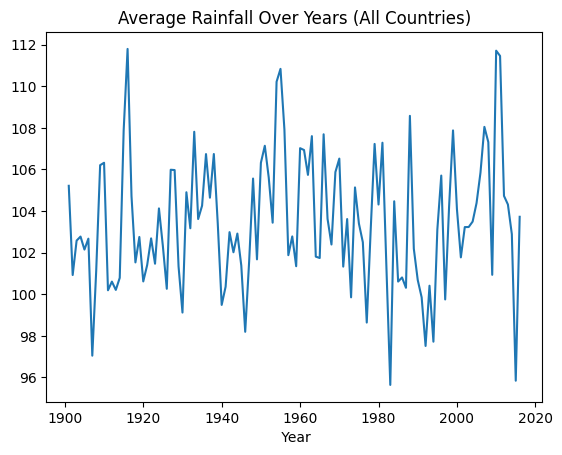

In [16]:
import matplotlib.pyplot as plt
plt.title('Average Rainfall Over Years (All Countries)')


rainfall_df.groupby(year_col)[rain_col].mean().plot()
plt.show()






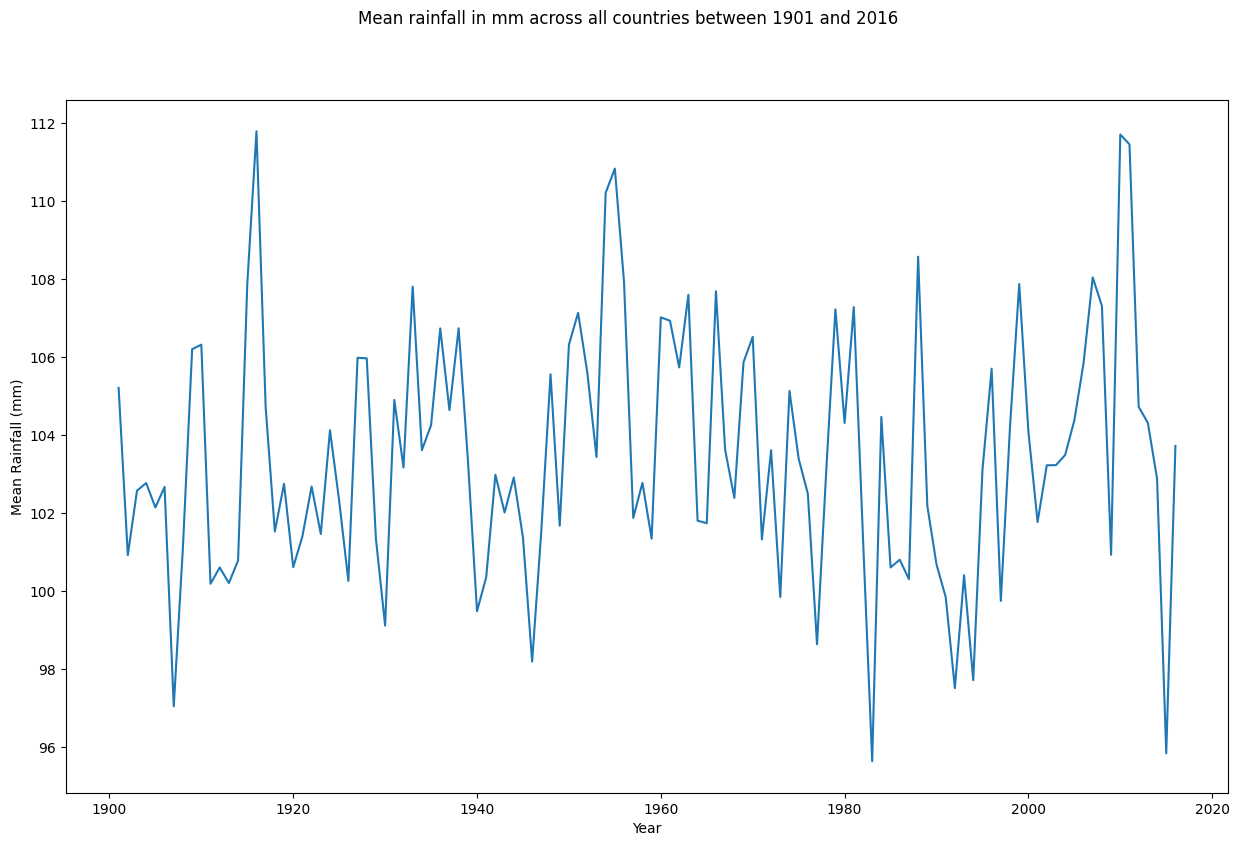

In [15]:
import matplotlib.pyplot as plt

year_col = next(c for c in rainfall_df.columns if 'year' in c.lower())
rain_col = next(c for c in rainfall_df.columns if 'rain' in c.lower())

temp_data = rainfall_df.groupby(year_col)[rain_col].mean()

fig, ax = plt.subplots(figsize=(15,9))
fig.suptitle('Mean rainfall in mm across all countries between 1901 and 2016')

temp_data.plot(ax=ax)

ax.set_ylabel('Mean Rainfall (mm)')
ax.set_xlabel('Year')

plt.show()


## Temperature data

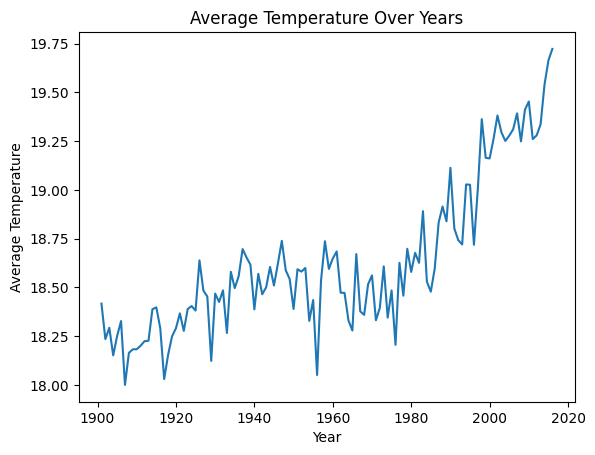

In [19]:
import matplotlib.pyplot as plt

year_col = next(c for c in temperature_df.columns if 'year' in c.lower())
temp_col = next(c for c in temperature_df.columns if 'temp' in c.lower())

temperature_df.groupby(year_col)[temp_col].mean().plot()
plt.title('Average Temperature Over Years')
plt.xlabel('Year')
plt.ylabel('Average Temperature')
plt.show()



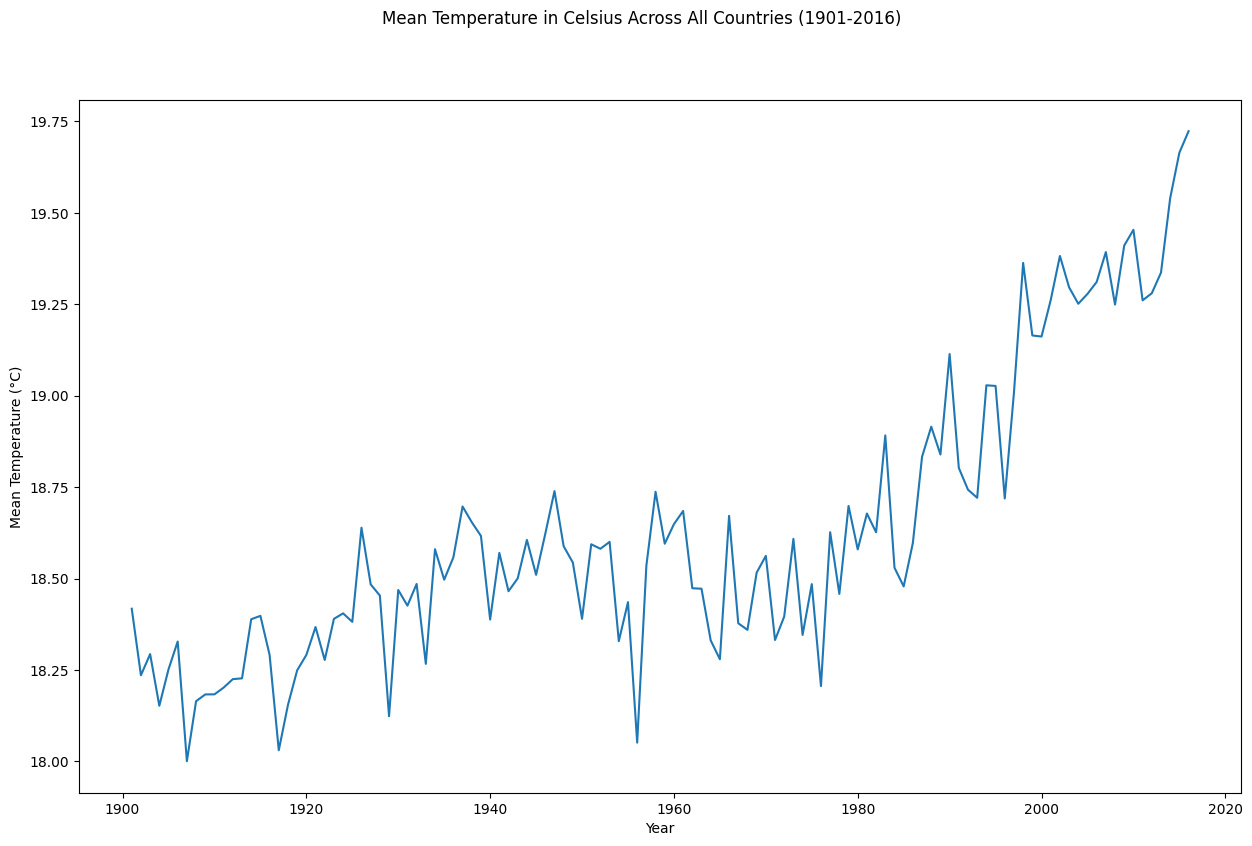

In [23]:
import matplotlib.pyplot as plt

year_col = next(c for c in temperature_df.columns if 'year' in c.lower())
temp_col = next(c for c in temperature_df.columns if 'temp' in c.lower())

# prepare data
temp_data = temperature_df.groupby(year_col)[temp_col].mean()

# plot data
fig, ax = plt.subplots(figsize=(15,9))
fig.suptitle('Mean Temperature in Celsius Across All Countries (1901-2016)')

temp_data.plot(ax=ax)

ax.set_ylabel('Mean Temperature (°C)')
ax.set_xlabel('Year')

plt.show()


## Yield data

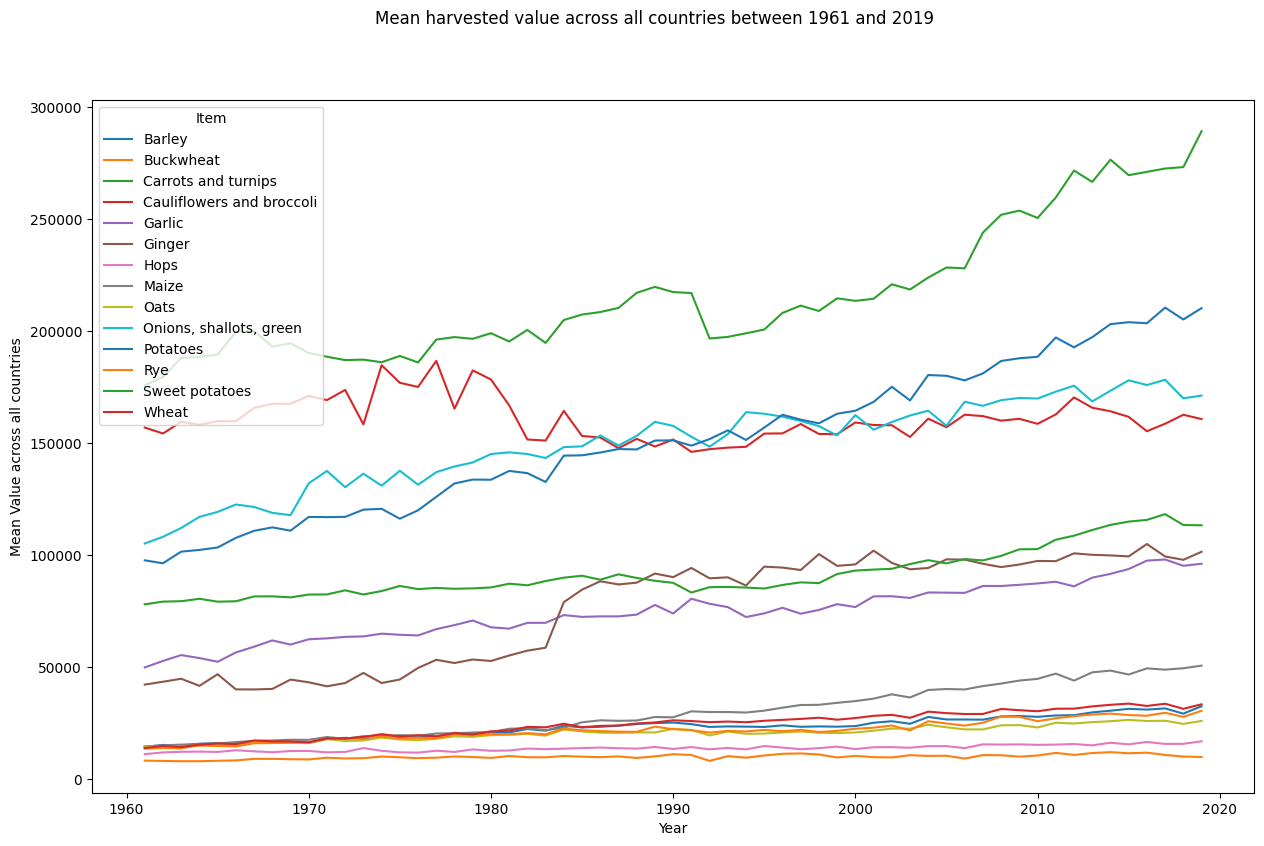

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

# load yield data
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# auto-detect columns
year_col = next(c for c in yield_df.columns if 'year' in c.lower())
item_col = next(c for c in yield_df.columns if 'item' in c.lower())
value_col = next(c for c in yield_df.columns if 'value' in c.lower())

# convert value column to numeric
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')

# prepare data
yield_mean = yield_df.groupby([year_col, item_col])[value_col].mean()

# plot data
fig, ax = plt.subplots(figsize=(15,9))
fig.suptitle('Mean harvested value across all countries between 1961 and 2019')

yield_mean.unstack().plot(ax=ax)

ax.set_ylabel('Mean Value across all countries')
ax.set_xlabel('Year')

plt.show()



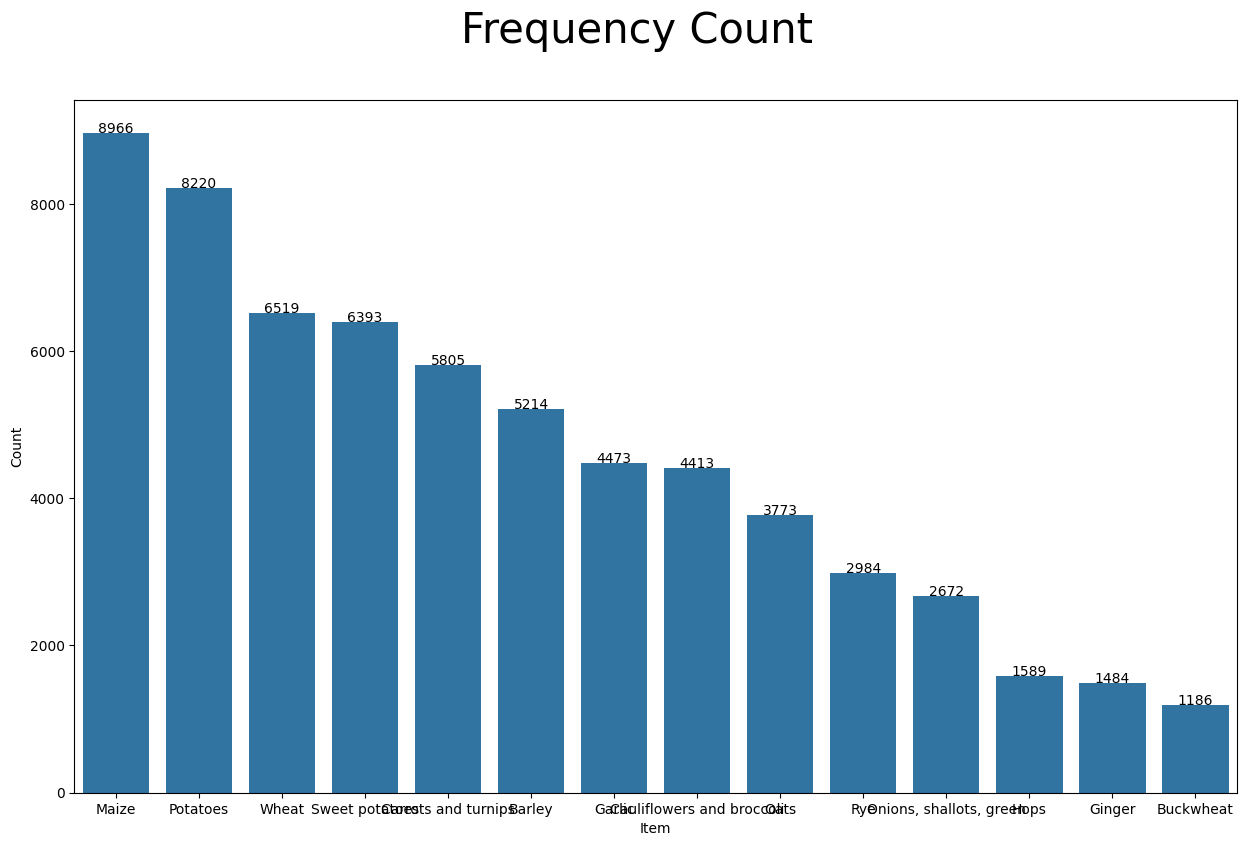

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# load yield data
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# auto-detect item column
item_col = next(c for c in yield_df.columns if 'item' in c.lower())

# frequency count
temp_df = yield_df[item_col].value_counts().to_frame().reset_index()
# rename columns to something predictable
temp_df.columns = ['Item', 'Count']

# plot
fig, axs = plt.subplots(1,1, figsize=(15,9))
fig.suptitle('Frequency Count', size=30)

g = sns.barplot(x='Item', y='Count', data=temp_df, ax=axs)

# add text on bars
for index, row in temp_df.iterrows():
    g.text(index, row['Count'] + 5, int(row['Count']), color='black', ha="center")

axs.set_xlabel('Item')
axs.set_ylabel('Count')

plt.show()



## Pesticide data

['Albania' 'Algeria' 'Angola' 'Antigua and Barbuda' 'Argentina' 'Armenia'
 'Australia' 'Austria' 'Azerbaijan' 'Bahamas' 'Bahrain' 'Bangladesh'
 'Barbados' 'Belarus' 'Belgium' 'Belgium-Luxembourg' 'Belize' 'Bermuda'
 'Bhutan' 'Bolivia (Plurinational State of)' 'Botswana' 'Brazil'
 'Brunei Darussalam' 'Bulgaria' 'Burkina Faso' 'Burundi' 'Cabo Verde'
 'Cameroon' 'Canada' 'Central African Republic' 'Chad' 'Chile' 'China'
 'China, Hong Kong SAR' 'China, Macao SAR' 'China, mainland'
 'China, Taiwan Province of' 'Colombia' 'Comoros' 'Congo' 'Cook Islands'
 'Costa Rica' "Côte d'Ivoire" 'Croatia' 'Cyprus' 'Czechia' 'Denmark'
 'Dominican Republic' 'Ecuador' 'Egypt' 'El Salvador' 'Eritrea' 'Estonia'
 'Ethiopia' 'Fiji' 'Finland' 'France' 'French Polynesia' 'Gambia'
 'Georgia' 'Germany' 'Ghana' 'Greece' 'Guatemala' 'Guinea' 'Guinea-Bissau'
 'Guyana' 'Haiti' 'Honduras' 'Hungary' 'Iceland' 'India' 'Indonesia'
 'Iran (Islamic Republic of)' 'Iraq' 'Ireland' 'Israel' 'Italy' 'Jamaica'
 'Japan' 'Jordan' 

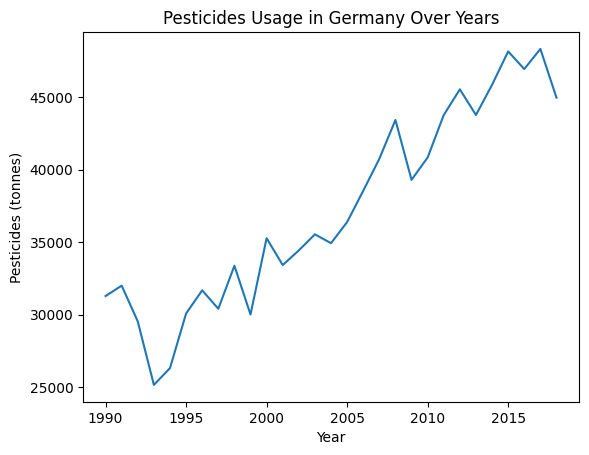

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# load data
pesticides_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/pesticides.csv'
)

# inspect unique areas and items
print(pesticides_df['Area'].unique())
print(pesticides_df['Item'].unique())

# filter Germany and pesticides
pest_data = pesticides_df[
    (pesticides_df['Area'] == 'Germany') &
    (pesticides_df['Item'].str.contains('pesticides', case=False))
]

print(pest_data.head())  # check if data exists

# only plot if data exists
if not pest_data.empty:
    pest_data.groupby('Year')['Value'].mean().plot()
    plt.title('Pesticides Usage in Germany Over Years')
    plt.xlabel('Year')
    plt.ylabel('Pesticides (tonnes)')
    plt.show()
else:
    print("No matching data for Germany found.")




Index(['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit', 'Value'], dtype='object')
['Pesticides (total)']


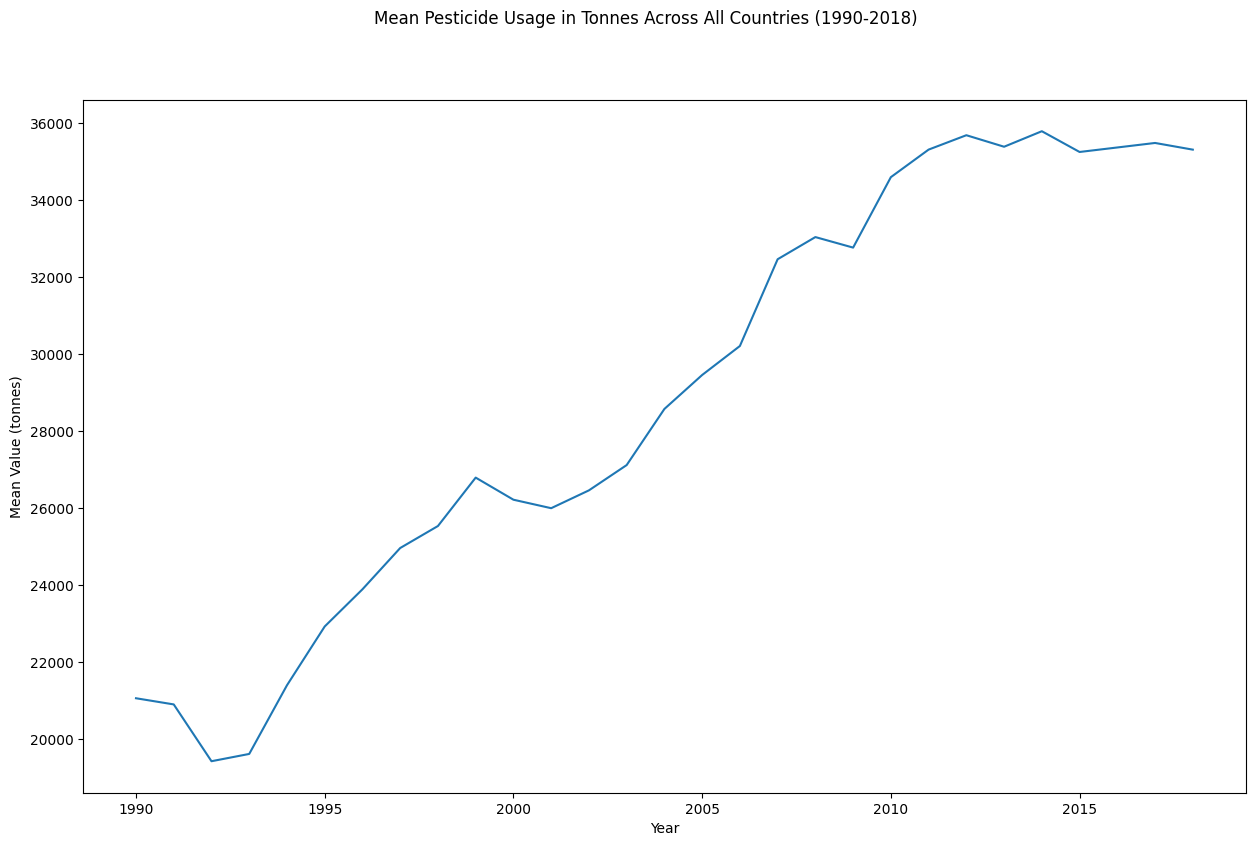

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

# load data
pesticides_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/pesticides.csv'
)

# check columns
print(pesticides_df.columns)
print(pesticides_df['Item'].unique())

# keep only pesticide entries
pest_data = pesticides_df[pesticides_df['Item'].str.contains('pesticides', case=False, na=False)]

# convert Value column to numeric
pest_data['Value'] = pd.to_numeric(pest_data['Value'], errors='coerce')

# drop NaNs
pest_data = pest_data.dropna(subset=['Value'])

# group by Year and plot
temp_data = pest_data.groupby('Year')['Value'].mean()

fig, ax = plt.subplots(figsize=(15,9))
fig.suptitle('Mean Pesticide Usage in Tonnes Across All Countries (1990-2018)')

temp_data.plot(ax=ax)
ax.set_ylabel('Mean Value (tonnes)')
ax.set_xlabel('Year')

plt.show()


## Merged data

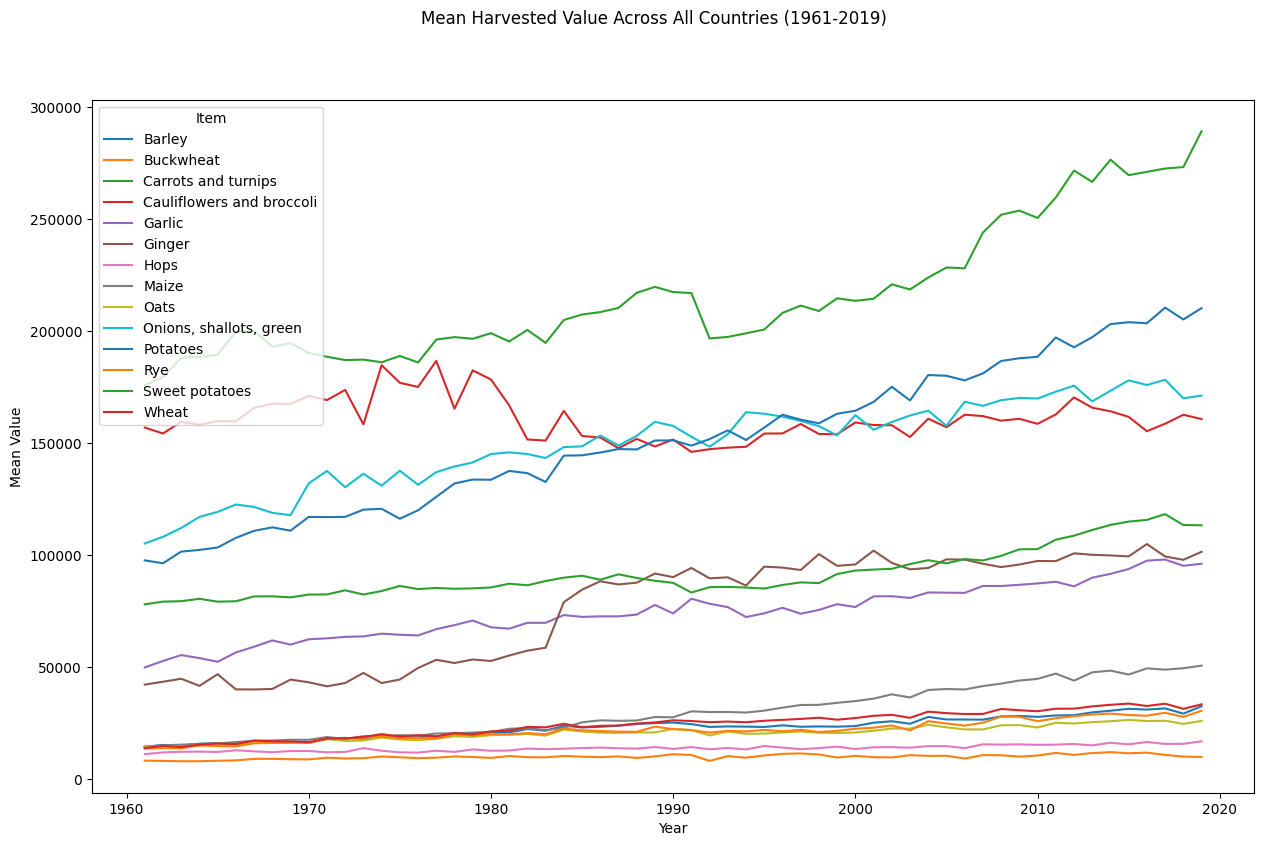

In [40]:
#import pandas as pd
import matplotlib.pyplot as plt

# load yield data
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# auto-detect columns
year_col = next(c for c in yield_df.columns if 'year' in c.lower())
item_col = next(c for c in yield_df.columns if 'item' in c.lower())
value_col = next(c for c in yield_df.columns if 'value' in c.lower())

# convert value column to numeric
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')
yield_df = yield_df.dropna(subset=[value_col])

# prepare data
temp_data = yield_df.groupby([year_col, item_col])[value_col].mean()

# plot data
fig, ax = plt.subplots(figsize=(15,9))
fig.suptitle('Mean Harvested Value Across All Countries (1961-2019)')

temp_data.unstack().plot(ax=ax)

ax.set_ylabel('Mean Value')
ax.set_xlabel('Year')

plt.show()


/tmp/ipython-input-2196005691.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Item', y='Count', data=freq_df, palette='viridis')


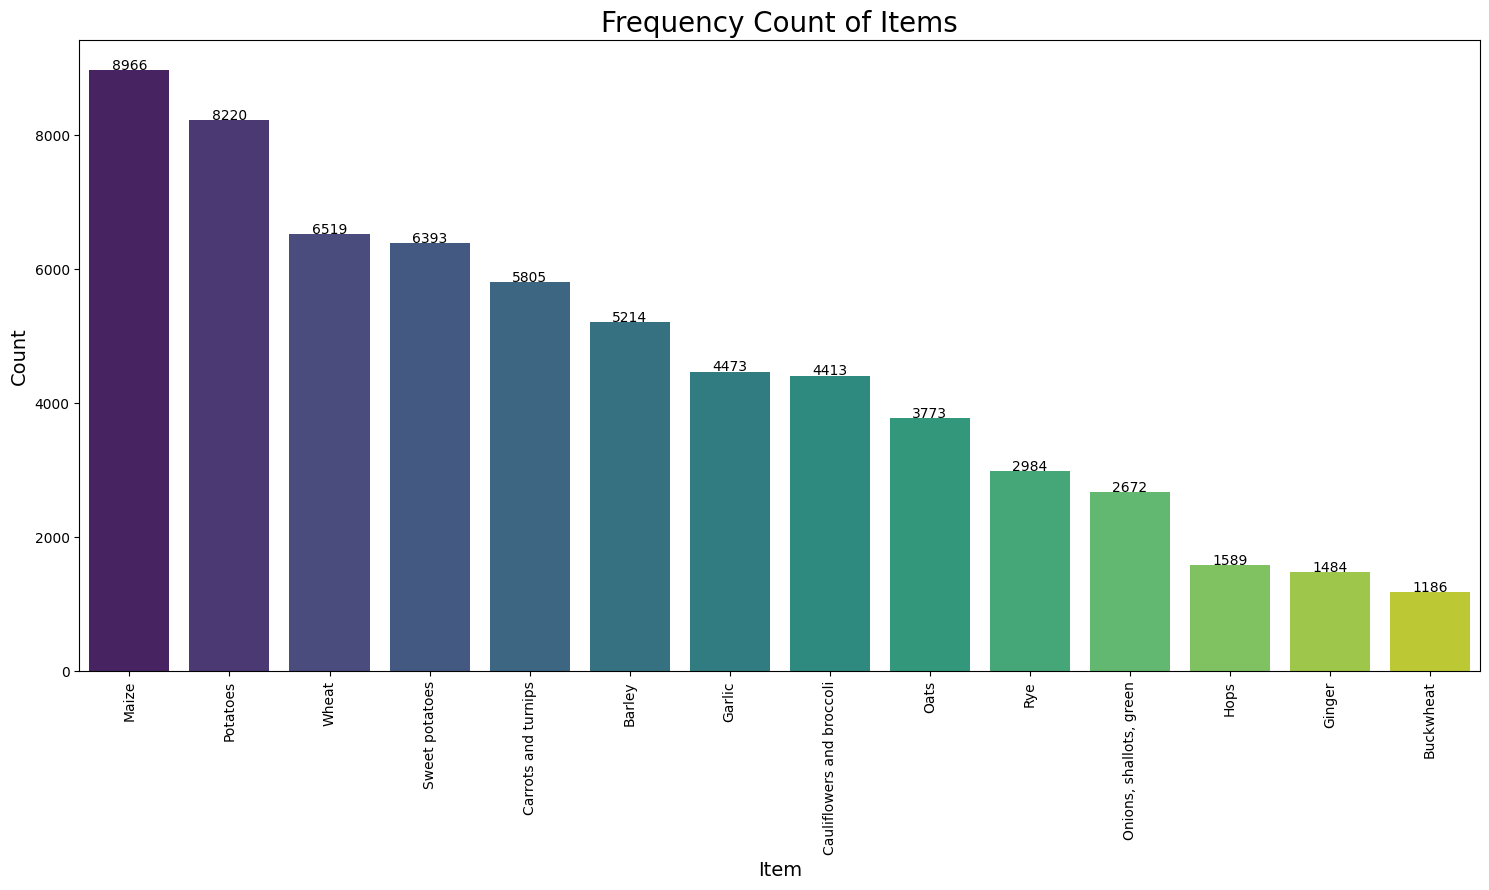

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load yield data
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# detect item column
item_col = next(c for c in yield_df.columns if 'item' in c.lower())

# count frequency of each item
freq_df = yield_df[item_col].value_counts().reset_index()
freq_df.columns = ['Item', 'Count']

# plot
plt.figure(figsize=(15,9))
sns.barplot(x='Item', y='Count', data=freq_df, palette='viridis')

plt.title('Frequency Count of Items', fontsize=20)
plt.xlabel('Item', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(rotation=90)  # rotate labels if too many items

# add counts on top of bars
for i, row in freq_df.iterrows():
    plt.text(i, row['Count'] + 5, int(row['Count']), ha='center')

plt.tight_layout()
plt.show()



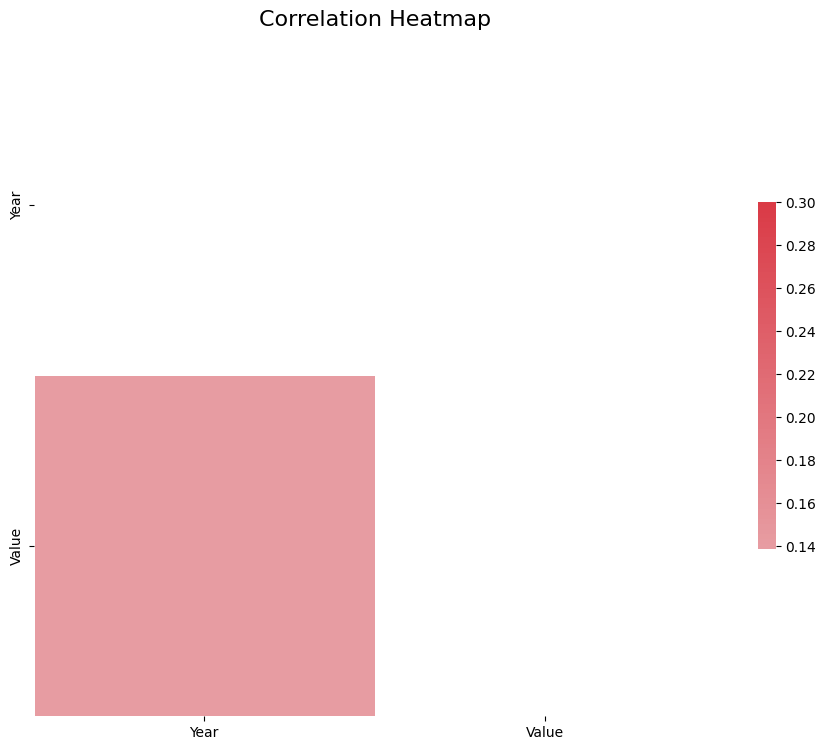

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# example with yield_df
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# convert value column to numeric
value_col = next(c for c in yield_df.columns if 'value' in c.lower())
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')

# select numeric columns and compute correlation
corr = yield_df.select_dtypes(include=[np.number]).corr()

# create a mask for the upper triangle
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

# plot
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

plt.title("Correlation Heatmap", fontsize=16)
plt.show()


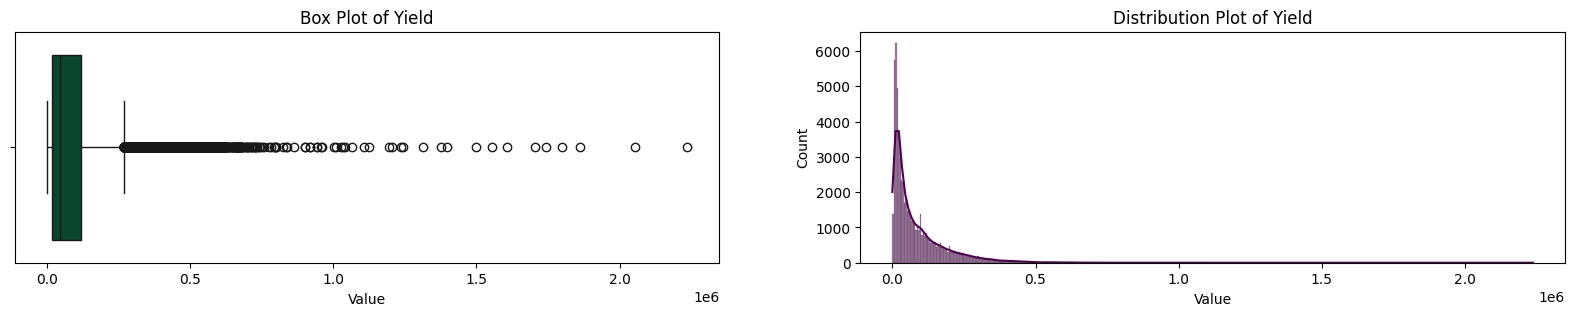

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load yield data
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# detect value column
value_col = next(c for c in yield_df.columns if 'value' in c.lower())

# convert to numeric
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')

# plot boxplot and histogram
plt.figure(figsize=(20, 3))

plt.subplot(1, 2, 1)
sns.boxplot(x=yield_df[value_col], color='#005030')
plt.title('Box Plot of Yield')

plt.subplot(1, 2, 2)
sns.histplot(x=yield_df[value_col], color='#500050', kde=True)
plt.title('Distribution Plot of Yield')

plt.show()


# Data Preprocessing

## One Hot Encoding

In [55]:
# check the shape of the dataset
yield_df.shape


(63691, 7)

In [57]:
import pandas as pd

# load yield data
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# convert value column to numeric
value_col = next(c for c in yield_df.columns if 'value' in c.lower())
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')

# auto-detect country and item columns
country_col = next((c for c in yield_df.columns if 'country' in c.lower() or 'area' in c.lower()), None)
item_col = next(c for c in yield_df.columns if 'item' in c.lower())

# one-hot encode Country and Item
df_onehot = pd.get_dummies(yield_df, columns=[country_col, item_col], prefix=['Country', 'Item'])

# separate features and target
X = df_onehot.loc[:, df_onehot.columns != value_col]
y = df_onehot[value_col]


In [59]:
yield_df.shape


(63691, 7)

## Backward Elimination

In [60]:
yield_df.shape


(63691, 7)

In [62]:
import pandas as pd
import statsmodels.api as sm

# load yield data
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# detect value column
value_col = next(c for c in yield_df.columns if 'value' in c.lower())

# convert to numeric
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')

# prepare X and y
y = yield_df[value_col]
X = yield_df.drop(value_col, axis=1)

# for simplicity, select only numeric columns for regression
X = X.select_dtypes(include='number')

cols = list(X.columns)
pmax = 1

while (len(cols) > 0):
    X_1 = X[cols]
    X_1 = sm.add_constant(X_1)
    model = sm.OLS(y, X_1).fit()
    p = pd.Series(model.pvalues.values[1:], index=cols)
    pmax = max(p)
    feature_with_p_max = p.idxmax()
    if pmax > 0.05:
        cols.remove(feature_with_p_max)
    else:
        break

# final dataset with selected features
final_data = X[cols]
final_data.insert(len(final_data.columns), value_col, y)

final_data.head()


,Year,Value
0,1961,10800
1,1962,10800
2,1963,10800
3,1964,10857
4,1965,10857


from matplotlib import pyplot as plt
_df_0['Year'].plot(kind='hist', bins=20, title='Year')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['Value'].plot(kind='hist', bins=20, title='Value')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2.plot(kind='scatter', x='Year', y='Value', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['Year']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'Year'}, axis=1)
              .sort_values('Year', ascending=True))
  xs = counted['Year']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = _df_3.sort_values('Year', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('Year')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['Value']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'Value'}, axis=1)
              .sort_values('Value', ascending=True))
  xs = counted['Value']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = _df_4.sort_values('Value', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('Value')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
_df_5['Year'].plot(kind='line', figsize=(8, 4), title='Year')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_6['Value'].plot(kind='line', figsize=(8, 4), title='Value')
plt.gca().spines[['top', 'right']].set_visible(False)

In [64]:
yield_df.shape

(63691, 7)

## Removing of Outliers

In [66]:
yield_df.shape

(63691, 7)

In [67]:
import pandas as pd
import numpy as np
from scipy import stats

# load yield data
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# detect value column
value_col = next(c for c in yield_df.columns if 'value' in c.lower())

# convert to numeric
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')

# prepare X and y
y = yield_df[value_col]
X = yield_df.drop(value_col, axis=1)

# select only numeric columns for z-score filtering
X_numeric = X.select_dtypes(include=[np.number])

# calculate z-scores
z_scores = stats.zscore(X_numeric)
abs_z_scores = np.abs(z_scores)

# filter out rows with z-score > 11
filtered_entries = (abs_z_scores < 11).all(axis=1)
X_filtered = X_numeric[filtered_entries]

# add the target column back
X_filtered.insert(len(X_filtered.columns), value_col, y[filtered_entries])

# final cleaned dataset
data = X_filtered
data.head()


,Year,Value
0,1961,10800
1,1962,10800
2,1963,10800
3,1964,10857
4,1965,10857


from matplotlib import pyplot as plt
_df_7['index'].plot(kind='hist', bins=20, title='index')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_8['Year'].plot(kind='hist', bins=20, title='Year')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_9['Value'].plot(kind='hist', bins=20, title='Value')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_10.plot(kind='scatter', x='index', y='Year', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

...

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['Year']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'Year'}, axis=1)
              .sort_values('Year', ascending=True))
  xs = counted['Year']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = _df_13.sort_values('Year', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('Year')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['Value']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'Value'}, axis=1)
              .sort_values('Value', ascending=True))
  xs = counted['Value']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = _df_14.sort_values('Value', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('Value')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
_df_15['index'].plot(kind='line', figsize=(8, 4), title='index')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_16['Year'].plot(kind='line', figsize=(8, 4), title='Year')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_17['Value'].plot(kind='line', figsize=(8, 4), title='Value')
plt.gca().spines[['top', 'right']].set_visible(False)

In [68]:
yield_df.shape

(63691, 7)

## Feature Scaling

In [69]:
yield_df.shape

(63691, 7)

In [72]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Load the dataset
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# Detect the numeric target column
value_col = next(c for c in yield_df.columns if 'value' in c.lower())

# Convert to numeric if needed
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')

# Select numeric feature columns (exclude the target)
X = yield_df.select_dtypes(include='number').drop(columns=[value_col], errors='ignore')

# Target column
y = yield_df[value_col]

# ----- OPTION 1: Min-Max Scaling -----
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

# ----- OPTION 2: Standard Scaling (mean=0, std=1) -----
# scaler = StandardScaler()
# X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

# Add the target back
X_scaled[value_col] = y

# Scaled dataset
data_scaled = X_scaled

# Check
print(data_scaled.head())



       Year  Value
0  0.000000  10800
1  0.017241  10800
2  0.034483  10800
3  0.051724  10857
4  0.068966  10857


In [73]:
yield_df.shape

(63691, 7)

# Modeling

In [76]:
# Assuming data_scaled is your cleaned & scaled dataset
y = data_scaled['Value']  # target
X = data_scaled.drop('Value', axis=1)  # features


In [77]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [78]:
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

In [79]:
def plot_regression_results(ax, y_test, y_pred, title, estimated_time, scores):

  # linear least-squares
  slope, intercept, rvalue, pvalue, stderr = linregress(y_test, y_pred)
  ax.plot([y_test.min(), y_test.max()], [intercept+y_test.min()*slope, intercept+y_test.max()*slope], '--r')

  ax.scatter(y_test, y_pred, alpha=0.7)

  # Anzeigen der Werte in einer Box
  extra = plt.Rectangle((0, 0), 0, 0, fc="w", fill=False,
                          edgecolor='none', linewidth=0)
  ax.legend([extra], [scores], loc='upper left')

  ax.set_xlabel('Actual values in tonnes')
  ax.set_ylabel('Predictes values in tonnes')
  ax.set_title('{}\nTrained in {:.2f} Milliseconds'.format(name, estimated_time*1000))

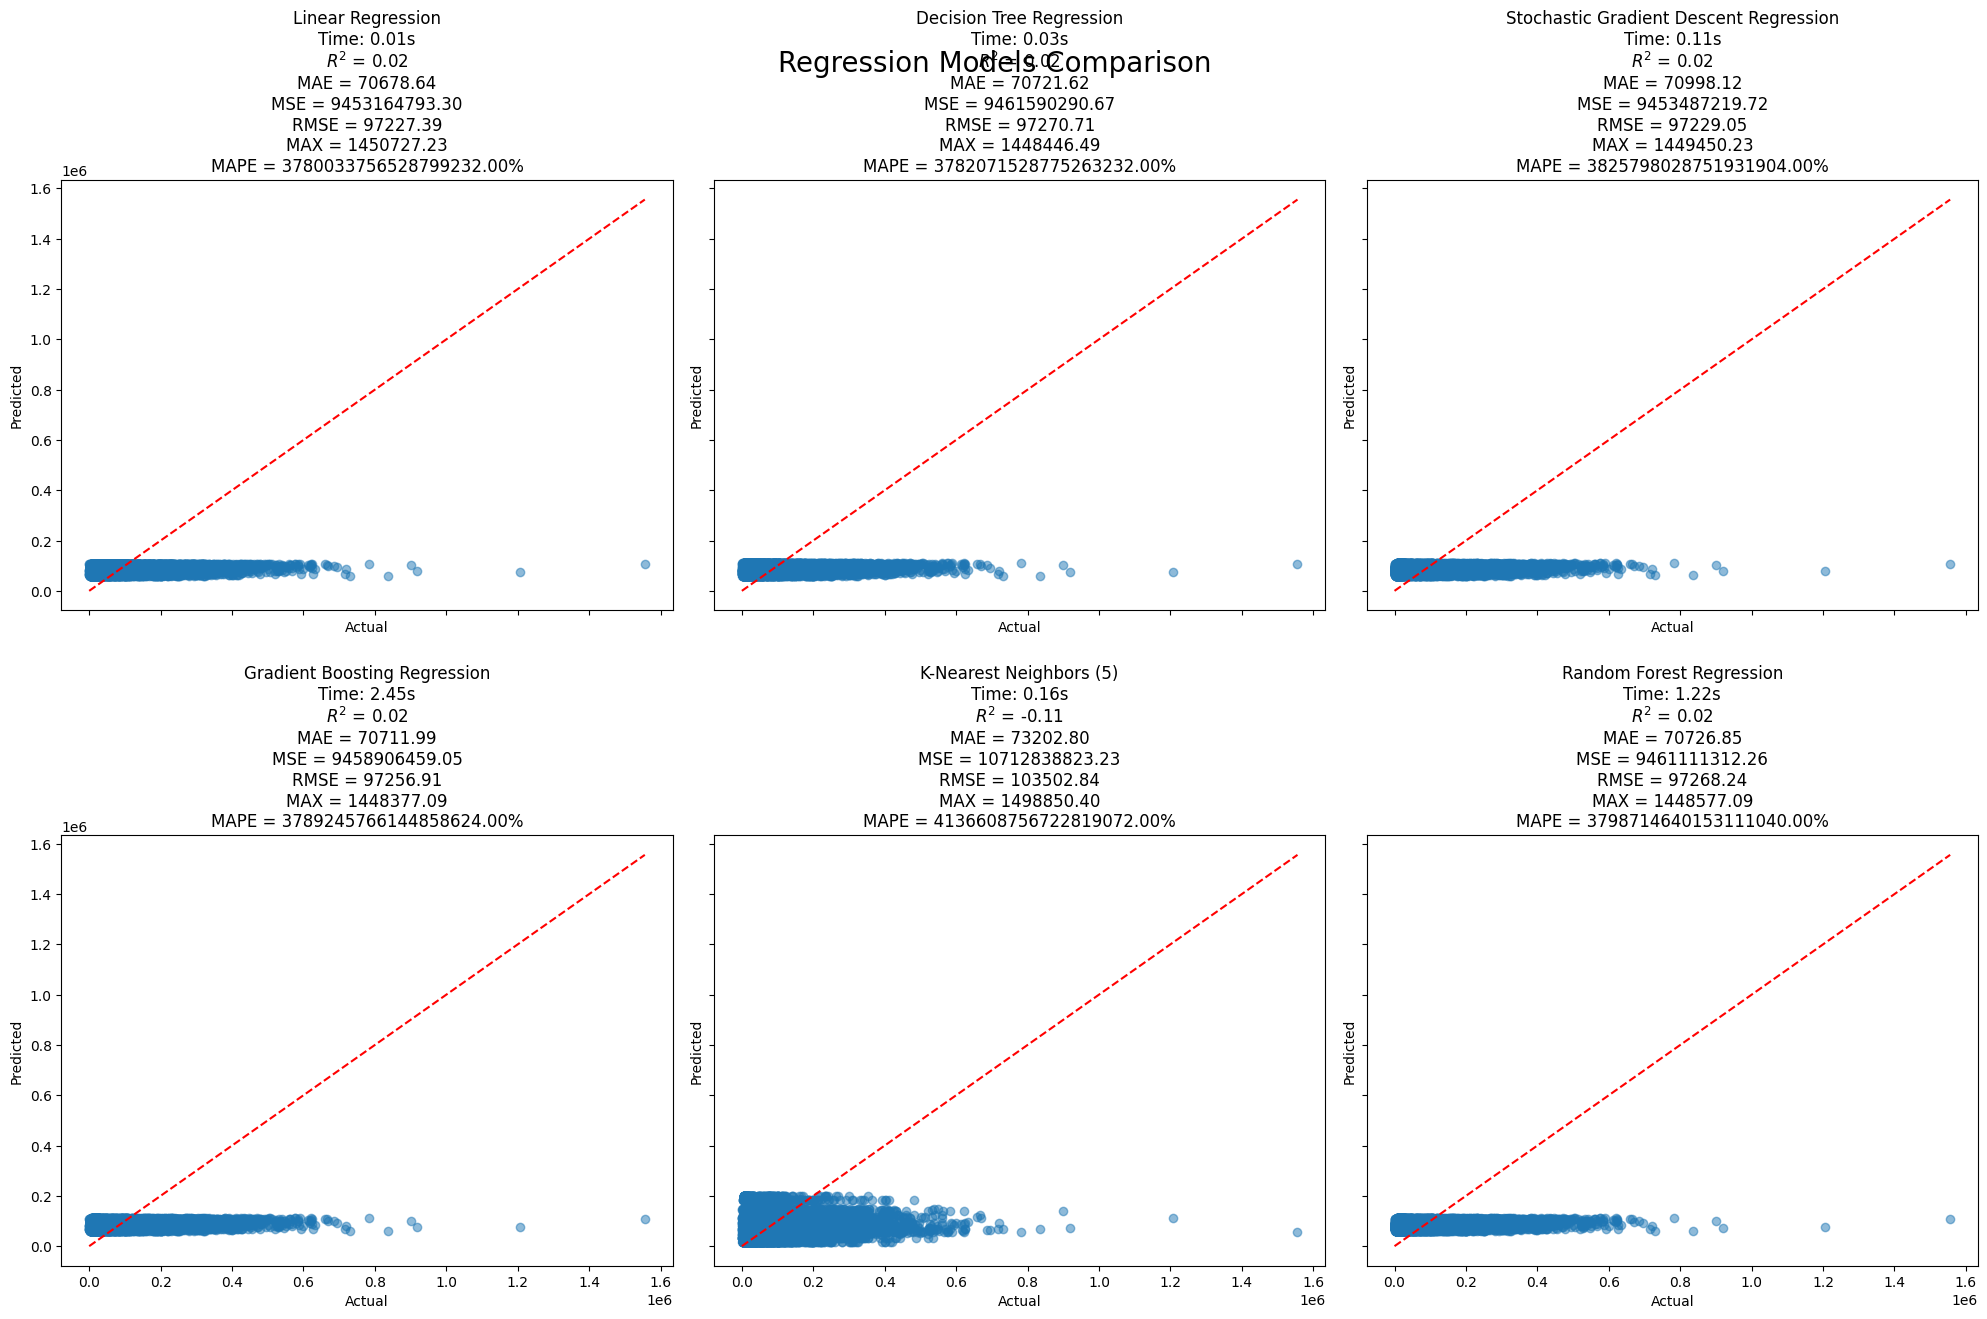

In [82]:
# ------------------- IMPORTS -------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, max_error, mean_absolute_percentage_error

# ------------------- LOAD DATA -------------------
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# Detect numeric target column
value_col = next(c for c in yield_df.columns if 'value' in c.lower())
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')
yield_df = yield_df.dropna(subset=[value_col])

# ------------------- FEATURE SELECTION & SCALING -------------------
# Only numeric features
X = yield_df.select_dtypes(include=np.number).drop(columns=[value_col], errors='ignore')
y = yield_df[value_col]

scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

# Add target back
data = X_scaled.copy()
data[value_col] = y

# ------------------- TRAIN/TEST SPLIT -------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# ------------------- DEFINE REGRESSORS -------------------
estimators = [
    ('Linear Regression', LinearRegression()),
    ('Decision Tree Regression', DecisionTreeRegressor()),
    ('Stochastic Gradient Descent Regression', SGDRegressor(loss='squared_error', max_iter=1000, tol=1e-3)),
    ('Gradient Boosting Regression', GradientBoostingRegressor()),
    ('K-Nearest Neighbors (5)', KNeighborsRegressor(n_neighbors=5)),
    ('Random Forest Regression', RandomForestRegressor())
]


# ------------------- HELPER FUNCTION TO PLOT -------------------
def plot_regression_results(ax, y_true, y_pred, name, elapsed_time, metrics_text):
    ax.scatter(y_true, y_pred, alpha=0.5)
    ax.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
    ax.set_title(f'{name}\nTime: {elapsed_time:.2f}s\n{metrics_text}')
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')

# ------------------- RUN REGRESSORS AND PLOT -------------------
fig, axs = plt.subplots(nrows=2, ncols=3, sharex=True, sharey=True, figsize=(20, 13))
axs = np.ravel(axs)

for ax, (name, est) in zip(axs, estimators):
    start_time = time.time()
    est.fit(X_train, y_train)
    y_pred = est.predict(X_test)
    elapsed_time = time.time() - start_time

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    metrics_text = (r'$R^2$ = {:.2f}' + '\n' +
                    r'MAE = {:.2f}' + '\n' +
                    r'MSE = {:.2f}' + '\n' +
                    r'RMSE = {:.2f}' + '\n' +
                    r'MAX = {:.2f}' + '\n' +
                    r'MAPE = {:.2f}%').format(
                        r2_score(y_test, y_pred),
                        mean_absolute_error(y_test, y_pred),
                        mse,
                        rmse,
                        max_error(y_test, y_pred),
                        mean_absolute_percentage_error(y_test, y_pred)*100
                    )

    plot_regression_results(ax, y_test, y_pred, name, elapsed_time, metrics_text)

plt.suptitle('Regression Models Comparison', fontsize=20)
plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()


/tmp/ipython-input-4213723921.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(r2_values, labels=names)
/tmp/ipython-input-4213723921.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(max_error_values, labels=names)
/tmp/ipython-input-4213723921.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[2].boxplot(neg_mean_absolute_error_values, labels=names)
/tmp/ipython-input-4213723921.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[3].boxplot(neg_m

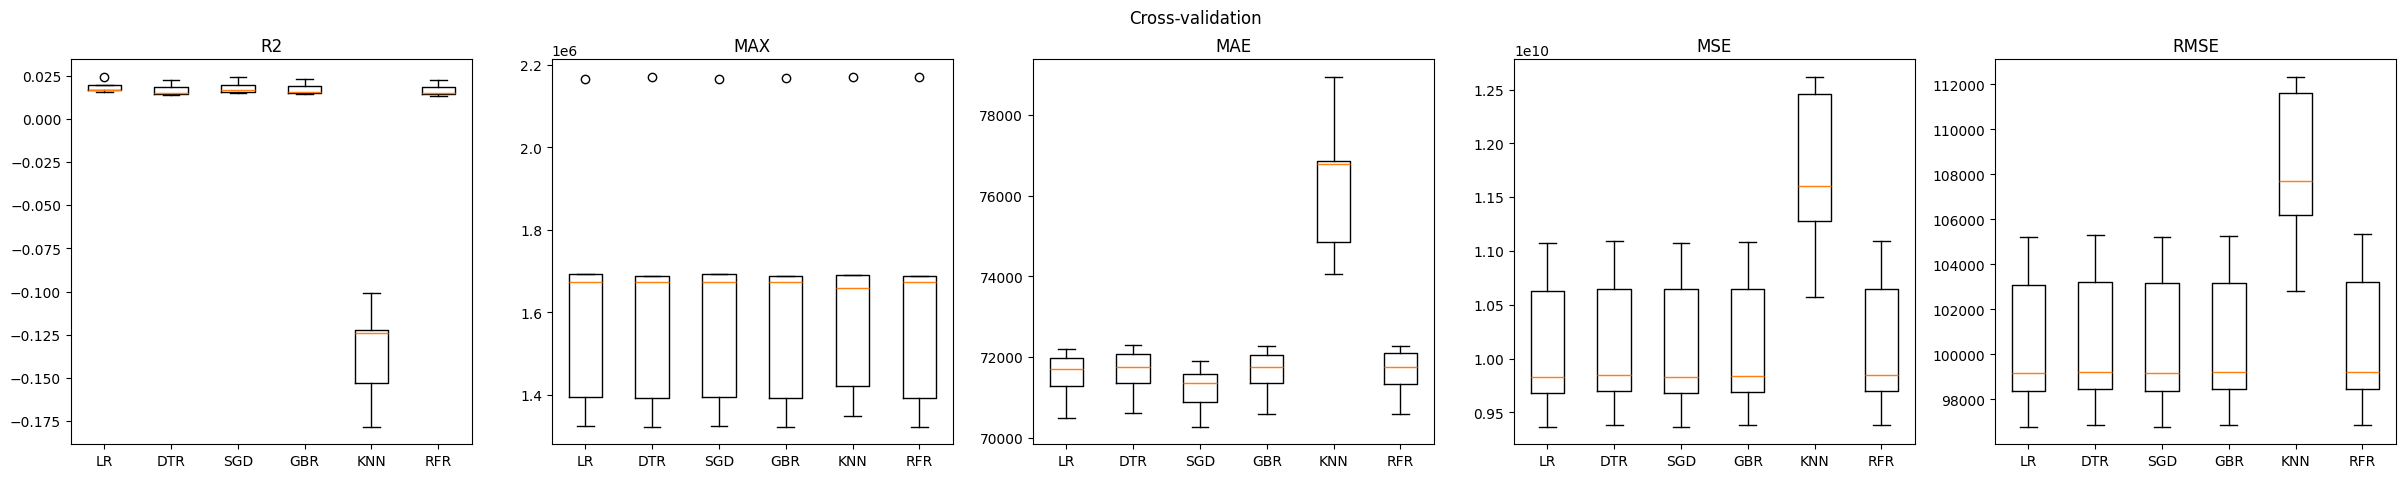

In [83]:
r2_values = []
max_error_values = []
neg_mean_absolute_error_values = []
neg_mean_squared_error_values = []
neg_root_mean_squared_error_values = []

for name, est in estimators:
  # Kreuzvalidierung
  score = cross_validate(est, X_train, y_train, cv=5,
                         scoring=['r2', 'max_error', 'neg_mean_absolute_error', 'neg_mean_squared_error', 'neg_root_mean_squared_error'],
                         n_jobs=-1)

  # Abspeichern der Werte
  r2_values.append(score['test_r2'])
  max_error_values.append(-score['test_max_error'])
  neg_mean_absolute_error_values.append(-score['test_neg_mean_absolute_error'])
  neg_mean_squared_error_values.append(-score['test_neg_mean_squared_error'])
  neg_root_mean_squared_error_values.append(-score['test_neg_root_mean_squared_error'])

# Plotten der Werte
fig, axs = plt.subplots(nrows=1, ncols=5, figsize=(30, 5))

names = ['LR', 'DTR', 'SGD', 'GBR', 'KNN', 'RFR']

axs[0].boxplot(r2_values, labels=names)
axs[0].set_title('R2')
axs[1].boxplot(max_error_values, labels=names)
axs[1].set_title('MAX')
axs[2].boxplot(neg_mean_absolute_error_values, labels=names)
axs[2].set_title('MAE')
axs[3].boxplot(neg_mean_squared_error_values, labels=names)
axs[3].set_title('MSE')
axs[4].boxplot(neg_root_mean_squared_error_values, labels=names)
axs[4].set_title('RMSE')

plt.suptitle('Cross-validation')
plt.show()

In [84]:
regression = 5

print(u'R²: {:.3f} \u00B1 {:.3f}'.format(np.mean(r2_values[regression]), np.std(r2_values[regression])))
print(u'MAX: {:,.0f} \u00B1 {:,.0f}'.format(np.mean(max_error_values[regression]), np.std(max_error_values[regression])))
print(u'MAE: {:,.0f} \u00B1 {:,.0f}'.format(np.mean(neg_mean_absolute_error_values[regression]), np.std(neg_mean_absolute_error_values[regression])))
print(u'MSE: {:,.0f} \u00B1 {:,.0f}'.format(np.mean(neg_mean_squared_error_values[regression]), np.std(neg_mean_squared_error_values[regression])))
print(u'RMSE: {:,.0f} \u00B1 {:,.0f}'.format(np.mean(neg_root_mean_squared_error_values[regression]), np.std(neg_root_mean_squared_error_values[regression])))

R²: 0.017 ± 0.003
MAX: 1,649,710 ± 298,858
MAE: 71,618 ± 605
MSE: 10,133,887,360 ± 636,366,773
RMSE: 100,618 ± 3,144


In [87]:
# Imports
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ------------------------
# 1. Load the data
# ------------------------
yield_df = pd.read_csv(
    'https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res/yield.csv'
)

# Auto-detect columns
year_col = next(c for c in yield_df.columns if 'year' in c.lower())
item_col = next(c for c in yield_df.columns if 'item' in c.lower())
value_col = next(c for c in yield_df.columns if 'value' in c.lower())

# Convert value column to numeric and drop missing
yield_df[value_col] = pd.to_numeric(yield_df[value_col], errors='coerce')
yield_df = yield_df.dropna(subset=[value_col])

# ------------------------
# 2. Prepare features
# ------------------------
# If categorical (Item), encode as numeric
yield_df[item_col] = yield_df[item_col].astype('category').cat.codes

# Define X and y
X = yield_df[[year_col, item_col]]
y = yield_df[value_col]

# Scale features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# ------------------------
# 3. Train-test split
# ------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# ------------------------
# 4. Fit Random Forest
# ------------------------
rfr = RandomForestRegressor(n_estimators=100, random_state=42)
rfr.fit(X_train, y_train)

# Predict
y_pred = rfr.predict(X_test)

# ------------------------
# 5. Evaluate
# ------------------------
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))


R2 Score: 0.4851776107480372
MAE: 42315.72617486808
MSE: 4973244365.560755
RMSE: 70521.233437602


In [5]:
# Auto-detect Year and Country columns for each dataset
def detect_columns(df):
    year_col = next(c for c in df.columns if 'year' in c.lower())
    country_col = next(c for c in df.columns if 'area' in c.lower() or 'country' in c.lower())
    return year_col, country_col

# Detect columns
rain_year, rain_country = detect_columns(rainfall_df)
temp_year, temp_country = detect_columns(temperature_df)
pest_year, pest_country = detect_columns(pesticides_df)
yield_year, yield_country = detect_columns(yield_df)

# Rename columns to standard names
for df, year_col, country_col in [
    (rainfall_df, rain_year, rain_country),
    (temperature_df, temp_year, temp_country),
    (pesticides_df, pest_year, pest_country),
    (yield_df, yield_year, yield_country)
]:
    df.rename(columns={year_col:'Year', country_col:'Country'}, inplace=True)

# Merge datasets on standardized 'Year' + 'Country'
data = rainfall_df.merge(temperature_df, on=['Year','Country'], how='inner')
data = data.merge(pesticides_df, on=['Year','Country'], how='inner')
data = data.merge(yield_df, on=['Year','Country'], how='inner')

print(data.head())


Empty DataFrame
Columns: [Rainfall - (MM), Year,  Statistics_x, Country,  ISO3_x, Temperature - (Celsius),  Statistics_y,  ISO3_y, Domain_x, Element_x, Item_x, Unit_x, Value_x, Domain_y, Element_y, Item_y, Unit_y, Value_y]
Index: []


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler

# Load data
base_url = "https://raw.githubusercontent.com/Drinkler/Yield-Prediction/main/res"
rainfall_df    = pd.read_csv(f"{base_url}/rainfall.csv")
temperature_df = pd.read_csv(f"{base_url}/temp.csv")
pesticides_df  = pd.read_csv(f"{base_url}/pesticides.csv")
yield_df       = pd.read_csv(f"{base_url}/yield.csv")

# Helpers
def find_col(df, keys):
    for c in df.columns:
        if any(k in c.lower() for k in keys):
            return c
    return None

def prep(df, year_keys, country_keys, value_keys, value_name):
    y = find_col(df, year_keys)
    c = find_col(df, country_keys)
    v = find_col(df, value_keys)
    out = {}
    if y: out[y] = 'Year'
    if c: out[c] = 'Country'
    if v: out[v] = value_name
    return df[list(out.keys())].rename(columns=out)

# Prepare datasets
rainfall_df   = prep(rainfall_df,   ['year'], ['area','country'], ['rain'], 'Rainfall_mm')
pesticides_df = prep(pesticides_df, ['year'], ['area','country'], ['pesticide'], 'Pesticides_tonnes')
yield_df      = prep(yield_df,      ['year'], ['area','country'], ['yield'], 'Crop_Yield_tonnes_per_ha')

temp_year = find_col(temperature_df, ['year'])
temp_val  = find_col(temperature_df, ['temp'])
temperature_df = temperature_df[[temp_year, temp_val]].rename(
    columns={temp_year:'Year', temp_val:'Avg_Temperature_C'}
)

# Merge
data = rainfall_df.merge(temperature_df, on='Year', how='inner') \
                  .merge(pesticides_df, on=['Year','Country'], how='inner') \
                  .merge(yield_df, on=['Year','Country'], how='inner')

# Train
X = data[['Rainfall_mm','Avg_Temperature_C','Pesticides_tonnes']]
y = data['Crop_Yield_tonnes_per_ha']
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

model = RandomForestRegressor(n_estimators=50, random_state=42)
model.fit(X_scaled, y)

# Predict
rainfall = float(input("Rainfall: "))
temperature = float(input("Temperature: "))
pesticides = float(input("Pesticides: "))

pred = model.predict(scaler.transform([[rainfall, temperature, pesticides]]))
print(f"Predicted wheat yield: {pred[0]:.2f}")
